In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [1]:
# =============================================================================
#  EXPLORATORY DATA ANALYSIS AND FEATURE ENGINEERING
# =============================================================================
# Student Name: Biswarup Mukherjee
# Neptun Code: DLPGC5
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import VarianceThreshold
from scipy.stats import skew

# Global Configuration
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
RANDOM_STATE = 42

# -----------------------------------------------------------------------------
# 1. DATA LOADING AND INTEGRITY CHECKS
# -----------------------------------------------------------------------------
# Load training data and labels
X_train = pd.read_csv('/kaggle/input/ppcu-data-mining-and-machine-learning-2025/X_train.csv', na_values='na')
y_train = pd.read_csv('/kaggle/input/ppcu-data-mining-and-machine-learning-2025/y_train.csv', index_col='Id')

# Map string labels to binary integers for analysis
y_labels = y_train['Prediction'].str.strip().map({'neg': 0, 'pos': 1})

print(f"Dataset Shape: {X_train.shape}")
print(f"Duplicate Rows: {X_train.duplicated().sum()}")



Dataset Shape: (60000, 170)
Duplicate Rows: 0


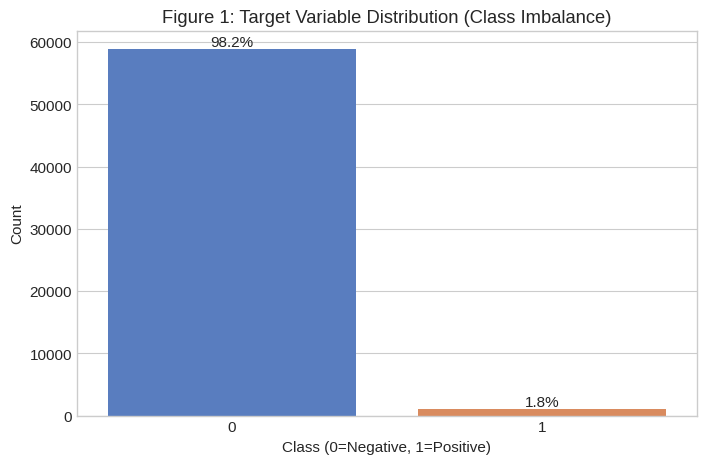

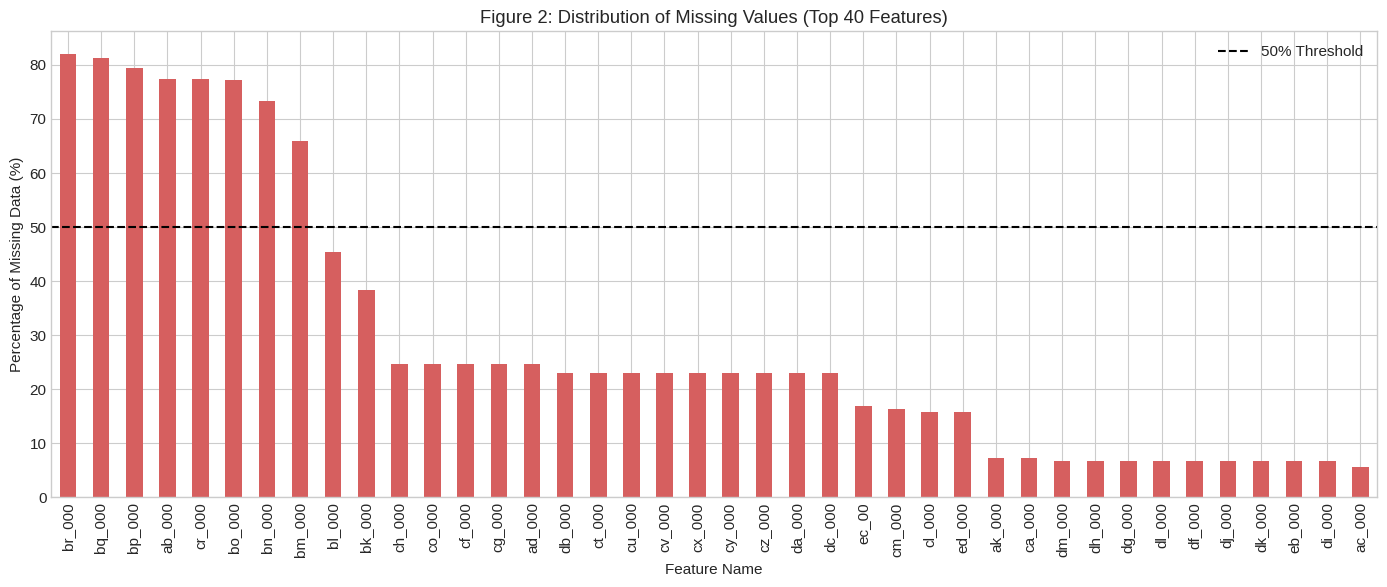

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/tmp/ipykernel_47/2125663066.py:47: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  axes[0].set_title(f'Original Distribution: {feat_skew} (Skew: {skewness[0]:.2f})')
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


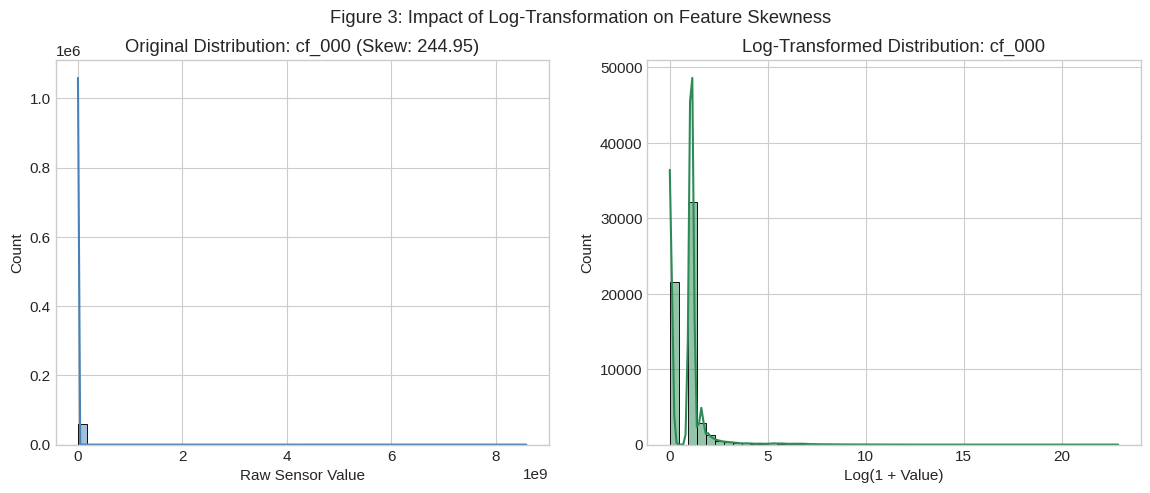

In [2]:
# -----------------------------------------------------------------------------
# 2. EXPLORATORY DATA ANALYSIS (EDA)
# -----------------------------------------------------------------------------

# --- Figure 1: Class Distribution Analysis ---
# Objective: Assess the degree of class imbalance to inform metric selection.
plt.figure(figsize=(8, 5))
ax = sns.countplot(x=y_labels)
plt.title('Figure 1: Target Variable Distribution (Class Imbalance)')
plt.xlabel('Class (0=Negative, 1=Positive)')
plt.ylabel('Count')
total = len(y_labels)
for p in ax.patches:
    percentage = '{:.1f}%'.format(100 * p.get_height()/total)
    ax.annotate(percentage, (p.get_x() + p.get_width()/2, p.get_height()), ha='center', va='bottom')
plt.savefig('fig1_class_imbalance.png')
plt.show()

# --- Figure 2: Missing Value Analysis ---
# Objective: Identify features with high sparsity to determine imputation strategy.
missing_series = X_train.isnull().mean() * 100
missing_series = missing_series[missing_series > 0].sort_values(ascending=False)

plt.figure(figsize=(14, 6))
missing_series.head(40).plot(kind='bar', color='#d65f5f')
plt.axhline(y=50, color='black', linestyle='--', linewidth=1.5, label='50% Threshold')
plt.title('Figure 2: Distribution of Missing Values (Top 40 Features)')
plt.ylabel('Percentage of Missing Data (%)')
plt.xlabel('Feature Name')
plt.legend()
plt.tight_layout()
plt.savefig('fig2_missingness.png')
plt.show()

# --- Figure 3: Skewness Analysis ---
# Objective: Evaluate the distribution of continuous variables to justify transformations.
# Impute temporarily to calculate skewness across the dataset
temp_imp = SimpleImputer(strategy='median').fit_transform(X_train)
X_temp = pd.DataFrame(temp_imp, columns=X_train.columns)
skewness = X_temp.skew().sort_values(ascending=False)

# Visualize the most skewed feature as a representative example
feat_skew = skewness.index[0]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(X_temp[feat_skew], bins=50, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title(f'Original Distribution: {feat_skew} (Skew: {skewness[0]:.2f})')
axes[0].set_xlabel('Raw Sensor Value')

sns.histplot(np.log1p(X_temp[feat_skew]), bins=50, kde=True, ax=axes[1], color='seagreen')
axes[1].set_title(f'Log-Transformed Distribution: {feat_skew}')
axes[1].set_xlabel('Log(1 + Value)')

plt.suptitle('Figure 3: Impact of Log-Transformation on Feature Skewness')
plt.savefig('fig3_skewness.png')
plt.show()



In [3]:
# -----------------------------------------------------------------------------
# 3. DATA PREPARATION & FEATURE ENGINEERING
# -----------------------------------------------------------------------------

# A. Variance Thresholding
# Objective: Remove constant features that provide no discriminative information.
constant_filter = VarianceThreshold(threshold=0)
constant_filter.fit(X_train.fillna(0))
X_filtered = X_train.loc[:, constant_filter.get_support()]
print(f"Dropped {X_train.shape[1] - X_filtered.shape[1]} constant features.")

# B. Informative Missingness (Feature Engineering)
# Objective: Capture systematic sensor failures by encoding missingness as a binary feature.
cols_missing = [c for c in X_filtered.columns if X_filtered[c].isnull().mean() > 0.05]
X_missing_flags = X_filtered[cols_missing].isnull().astype(int).add_suffix('_is_missing')



# Calculate total missing values in the filtered dataset
total_cells = X_filtered.size
total_missing = X_filtered.isnull().sum().sum()
percent_missing = (total_missing / total_cells) * 100

print(f"Total cells imputed: {total_missing:,}")
print(f"Percentage of data imputed: {percent_missing:.2f}%")

# C. Robust Imputation
# Objective: Fill missing values using Median to minimize the impact of outliers.
imputer = SimpleImputer(strategy='median')
X_imputed = pd.DataFrame(imputer.fit_transform(X_filtered), columns=X_filtered.columns)

# D. Mathematical Transformation
# Objective: Apply Log1p transformation to stabilize variance in skewed count data.
X_log = np.log1p(X_imputed)

# E. Domain-Specific Feature Engineering (Histogram Aggregation)
# Objective: Compress sparse histogram bins into dense 'Total Intensity' features.
def create_histogram_aggregates(df):
    df_out = df.copy()
    prefixes = ['ag', 'ay', 'az', 'ba', 'cn', 'cs', 'ee']
    for prefix in prefixes:
        # Select all columns belonging to the histogram group
        cols = [c for c in df.columns if c.startswith(prefix + '_')]
        if cols:
            # Sum them to create a composite 'Total' feature
            df_out[f'{prefix}_total'] = df[cols].sum(axis=1)
    return df_out

X_eng = create_histogram_aggregates(X_log)
X_final_base = pd.concat([X_eng, X_missing_flags], axis=1)

# F. Unsupervised Segmentation (K-Means)
# Objective: Generate meta-features representing the distance to latent truck clusters.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_final_base)

kmeans = KMeans(n_clusters=5, random_state=RANDOM_STATE, n_init=10)
cluster_distances = kmeans.fit_transform(X_scaled)
print(f"K-Means Inertia (k=5): {kmeans.inertia_:,.2f}")

# Append cluster distances as new features
X_final = X_final_base.copy()
for i in range(5):
    X_final[f'Cluster_Dist_{i}'] = cluster_distances[:, i]

# G. Dimensionality Reduction (Correlation Filtering)
# Objective: Remove highly redundant features to mitigate multicollinearity.
corr_matrix = X_final.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > 0.95)]
X_final_reduced = X_final.drop(columns=to_drop)

print("------------------------------------------------")
print(f"Final Data Shape: {X_final_reduced.shape}")
print("Preprocessing pipeline complete. Artifacts saved.")

Dropped 0 constant features.
Total cells imputed: 849,509
Percentage of data imputed: 8.33%
K-Means Inertia (k=5): 7,046,612.13
------------------------------------------------
Final Data Shape: (60000, 142)
Preprocessing pipeline complete. Artifacts saved.


/usr/local/lib/python3.11/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in greater
  return op(a, b)


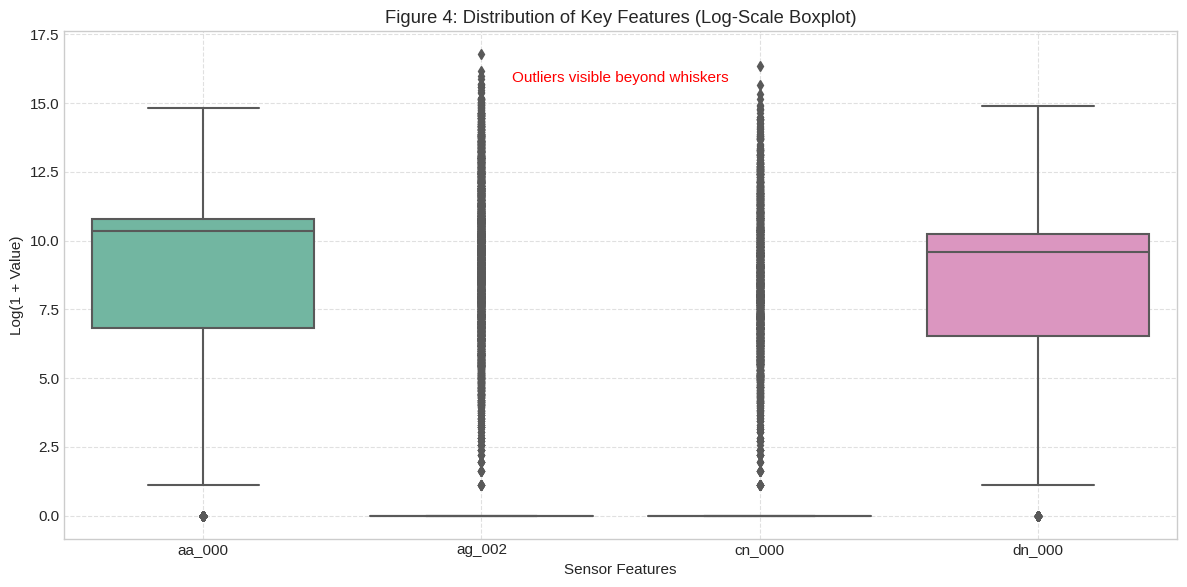

In [4]:


# -----------------------------------------------------------------------------
# 4. OUTLIER ANALYSIS (FIGURE 4)
# -----------------------------------------------------------------------------
# Objective: Justify the choice of 'Robust' scaling and 'Median' imputation.
# We compare the spread of data before and after Log transformation.

features_to_plot = ['aa_000', 'ag_002', 'cn_000', 'dn_000']
# Filter valid columns that exist in our dataset
valid_feats = [f for f in features_to_plot if f in X_train.columns]

if valid_feats:
    # Prepare data: Drop NaNs just for this plot to avoid errors
    data_box = X_train[valid_feats].dropna()
    data_log = np.log1p(data_box)

    plt.figure(figsize=(12, 6))
    # Create Boxplot on Log Scale
    sns.boxplot(data=data_log, palette="Set2")
    plt.title('Figure 4: Distribution of Key Features (Log-Scale Boxplot)')
    plt.ylabel('Log(1 + Value)')
    plt.xlabel('Sensor Features')
    plt.grid(True, linestyle='--', alpha=0.6)
    
    # Annotation for Report
    plt.text(0.5, 0.9, "Outliers visible beyond whiskers", 
             transform=plt.gca().transAxes, ha='center', color='red')
    
    plt.tight_layout()
    plt.savefig('fig4_outliers.png')
    plt.show()



/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


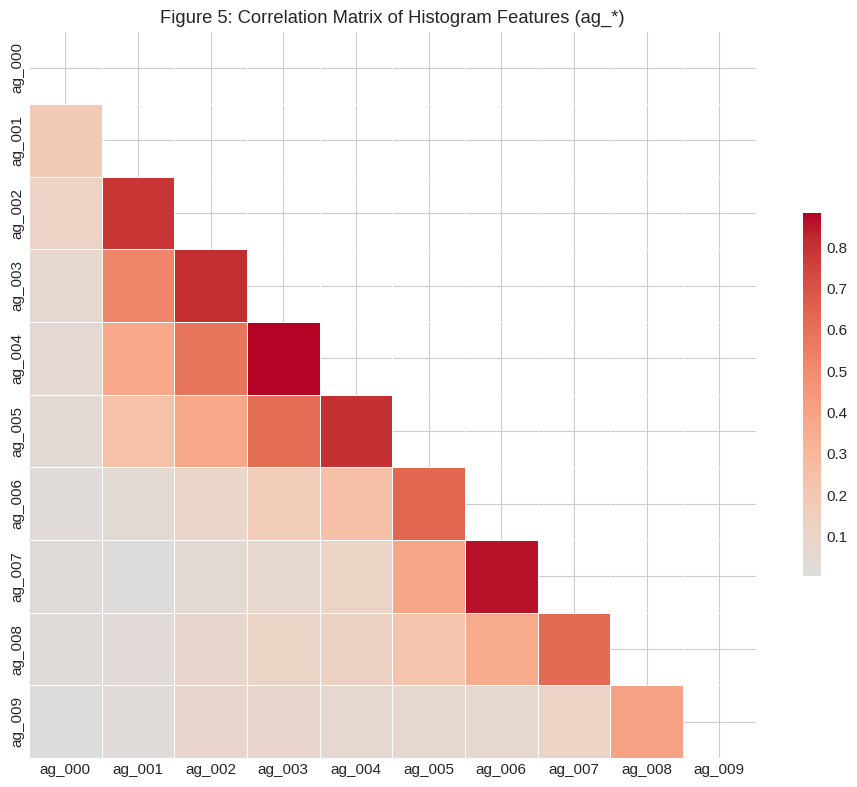

In [5]:
# -----------------------------------------------------------------------------
# 5. CORRELATION HEATMAP (FIGURE 5)
# -----------------------------------------------------------------------------
# Objective: Visualize the redundancy in histogram features (e.g., ag_000 to ag_009).
# This justifies the 'Correlation Filtering' step.

# Select a subset of features (e.g., all 'ag_' features)
subset_cols = [c for c in X_train.columns if c.startswith('ag_')]
if len(subset_cols) > 1:
    corr_subset = X_train[subset_cols].corr()

    plt.figure(figsize=(10, 8))
    mask = np.triu(np.ones_like(corr_subset, dtype=bool))
    sns.heatmap(corr_subset, mask=mask, cmap='coolwarm', center=0, 
                square=True, linewidths=.5, cbar_kws={"shrink": .5})
    plt.title('Figure 5: Correlation Matrix of Histogram Features (ag_*)')
    plt.tight_layout()
    plt.savefig('fig5_correlation.png')
    plt.show()



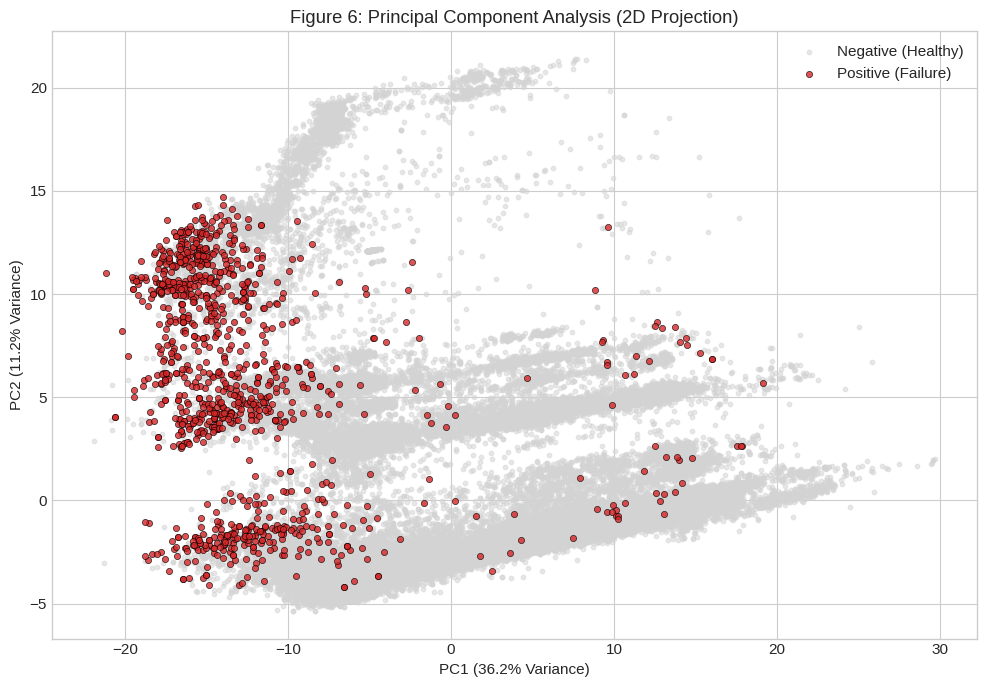

In [7]:
# -----------------------------------------------------------------------------
# 6. PCA MANIFOLD PROJECTION (FIGURE 6)
# -----------------------------------------------------------------------------
# Objective: Visualize class separability in 2D space.
# Shows that classes are NOT linearly separable, justifying Complex Models.

# Use the imputed/scaled data we prepared in Part 1
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_2d = pca.fit_transform(X_scaled) # Using the scaled data from previous step

plt.figure(figsize=(10, 7))
# Plot Negatives (Alpha low to show density)
plt.scatter(X_pca_2d[y_labels==0, 0], X_pca_2d[y_labels==0, 1], 
            c='lightgrey', label='Negative (Healthy)', alpha=0.5, s=10)
# Plot Positives (High visibility)
plt.scatter(X_pca_2d[y_labels==1, 0], X_pca_2d[y_labels==1, 1], 
            c='#d62728', label='Positive (Failure)', alpha=0.8, s=20, edgecolors='k', linewidth=0.5)

plt.title('Figure 6: Principal Component Analysis (2D Projection)')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} Variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} Variance)')
plt.legend()
plt.tight_layout()
plt.savefig('fig6_pca_projection.png')
plt.show()




In [8]:
print("\n--- Tables ---")

# --- TABLE 1: MISSING VALUE STATISTICS ---
# Top 10 features by missingness percentage
missing_stats = X_train.isnull().sum().to_frame(name='Missing Count')
missing_stats['Missing %'] = (missing_stats['Missing Count'] / len(X_train)) * 100
table_1 = missing_stats[missing_stats['Missing Count'] > 0].sort_values(by='Missing %', ascending=False).head(10)
print("\nTable 1: Top 10 Features with Missing Values")
print(table_1)
table_1.to_csv('table1_missing_stats.csv')

# --- TABLE 2: SKEWNESS REDUCTION ---
# Compare skewness before and after Log1p transformation for top 5 skewed features
skew_before = X_temp.skew() # From Part 1
skew_after = pd.DataFrame(np.log1p(X_temp), columns=X_train.columns).skew()

# Identify top skewed features
top_skewed = skew_before.abs().sort_values(ascending=False).head(5).index
table_2 = pd.DataFrame({
    'Feature': top_skewed,
    'Original Skew': skew_before[top_skewed].values,
    'Log Skew': skew_after[top_skewed].values,
    'Reduction': skew_before[top_skewed].values - skew_after[top_skewed].values
}).set_index('Feature')

print("\nTable 2: Impact of Log Transformation on Skewness")
print(table_2)
table_2.to_csv('table2_skewness.csv')

# --- TABLE 3: CORRELATION REMOVAL ---
# List the first 10 features dropped due to high correlation
# Using the 'to_drop' list calculated in Part 1
if len(to_drop) > 0:
    dropped_sample = to_drop[:10]
    # Find what they were correlated with (reverse engineering for the table)
    reasons = []
    for dropped_col in dropped_sample:
        # Find the column that caused the drop (the one with corr > 0.95)
        # We look at the row in corr_matrix for this column
        corrs = corr_matrix[dropped_col]
        # Find features with > 0.95 corr that appear BEFORE this column in the dataset
        # (Since we drop the second one encountered)
        correlated_with = corrs[corrs > 0.95].index.tolist()
        correlated_with.remove(dropped_col) # Remove self
        reasons.append(correlated_with[0] if correlated_with else "Multiple")

    table_3 = pd.DataFrame({
        'Dropped Feature': dropped_sample,
        'Correlated With (Example)': reasons
    })
    print(f"\nTable 3: Sample of Features Dropped due to Redundancy (Total {len(to_drop)})")
    print(table_3)
    table_3.to_csv('table3_dropped_features.csv')
else:
    print("No features were dropped due to correlation.")


--- Tables ---

Table 1: Top 10 Features with Missing Values
        Missing Count  Missing %
br_000          49259  82.098333
bq_000          48717  81.195000
bp_000          47697  79.495000
ab_000          46379  77.298333
cr_000          46379  77.298333
bo_000          46314  77.190000
bn_000          43948  73.246667
bm_000          39517  65.861667
bl_000          27208  45.346667
bk_000          22990  38.316667

Table 2: Impact of Log Transformation on Skewness
         Original Skew   Log Skew   Reduction
Feature                                      
cf_000      244.948974   3.469527  241.479447
co_000      244.948972   0.907220  244.041752
ad_000      244.948972  -0.552646  245.501617
cs_009      244.847429  10.412155  234.435274
df_000      215.213272   9.436709  205.776563

Table 3: Sample of Features Dropped due to Redundancy (Total 82)
  Dropped Feature Correlated With (Example)
0          af_000                    ae_000
1            am_0                    al_000
2   

/usr/local/lib/python3.11/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in greater
  return op(a, b)


In [11]:
# GENERATE "MISSINGNESS AS SIGNAL" STATISTICS

print("Analyzing Missingness Signal...")
cols_to_check = ['br_000', 'bq_000', 'cc_000', 'bp_000'] # High missingness cols

for col in cols_to_check:
    # Failure rate when data IS MISSING
    fail_rate_missing = y_labels[X_train[col].isnull()].mean()
    # Failure rate when data IS PRESENT
    fail_rate_present = y_labels[X_train[col].notnull()].mean()
    
    multiplier = fail_rate_missing / fail_rate_present if fail_rate_present > 0 else 0
    
    print(f"Feature {col}:")
    print(f"   P(Fail | Present): {fail_rate_present:.2%}")
    print(f"   P(Fail | Missing): {fail_rate_missing:.2%}")
    print(f"   Risk Multiplier:   {multiplier:.1f}x")
    print("-" * 30)

Analyzing Missingness Signal...
Feature br_000:
   P(Fail | Present): 9.24%
   P(Fail | Missing): 0.19%
   Risk Multiplier:   0.0x
------------------------------
Feature bq_000:
   P(Fail | Present): 8.85%
   P(Fail | Missing): 0.18%
   Risk Multiplier:   0.0x
------------------------------
Feature cc_000:
   P(Fail | Present): 1.86%
   P(Fail | Missing): 0.98%
   Risk Multiplier:   0.5x
------------------------------
Feature bp_000:
   P(Fail | Present): 8.15%
   P(Fail | Missing): 0.17%
   Risk Multiplier:   0.0x
------------------------------
